# MSPE 49600: Data Analytics for Motorsports
## Project 2: Predictive Modeling and Engineering Optimization

**Student:** Philip Allen  
**Course:** MSPE 49600 - Data Analytics for Motorsports  
**Semester:** Fall 2026

### Objective
This project builds quadratic surrogate models for mean Sector 3 time and mean top speed from repeated IMS road-course setup runs. The models are validated on unseen setup configurations, then used for bounds-only and top-speed-constrained engineering optimization. Grid searches and a penalty-function study are used to verify and interpret the numerical optimization results.

The final setup is reported as a **model-based candidate that still requires track or higher-fidelity simulation verification**.

In [1]:
# Imports and project configuration
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as opt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

USERNAME = "philipallen04"
PREFIX = f"{USERNAME}_pr02"
DATA_FILE = Path("ims_setup_project02.csv")

np.set_printoptions(suppress=True, precision=6)
pd.set_option("display.max_columns", None)

print("Python:", sys.version.split()[0])
print("Working data file:", DATA_FILE)

Python: 3.13.5
Working data file: ims_setup_project02.csv


# Task I - Setup-Level Data Preparation

The raw file contains repeated laps at each tested setup. The required variables are converted to numeric values, exact duplicates and incomplete rows are removed, and then the repeated laps are aggregated to one row per unique setup configuration.

In [2]:
# 1-3. Read, inspect, clean

df_raw = pd.read_csv(DATA_FILE)

print("First five raw rows:")
display(df_raw.head())
print(f"Raw shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print("Columns:", list(df_raw.columns))
print("\nDescriptive statistics:")
display(df_raw.describe(include="all"))
print("\nMissing values in raw data:")
display(df_raw.isna().sum().to_frame("missing_count"))

required_columns = [
    "lap",
    "rear_wing_angle_deg",
    "rear_ride_height_mm",
    "sector_3_time_s",
    "top_speed_kph",
]

df = df_raw[required_columns].copy()
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

n_before = len(df)
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().dropna(subset=required_columns).copy()

print(f"\nExact duplicate rows removed: {duplicates_before}")
print(f"Rows removed for duplicates/missing required values: {n_before - len(df)}")
print(f"Clean lap-level rows: {len(df)}")

First five raw rows:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
0,1,5,35,33.0949,286.761
1,2,5,35,32.9325,287.079
2,3,5,35,33.0858,287.261
3,4,5,35,33.0472,287.059
4,5,5,35,33.0534,287.463


Raw shape: 135 rows x 5 columns
Columns: ['lap', 'rear_wing_angle_deg', 'rear_ride_height_mm', 'sector_3_time_s', 'top_speed_kph']

Descriptive statistics:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
count,135.000000,135.000000,135.000000,135.000000,135.000000
mean,3.000000,9.000000,40.000000,31.803734,284.178563
std,1.419481,2.591605,4.097688,0.542766,1.778668
min,1.000000,5.000000,35.000000,31.061300,280.887000
25%,2.000000,7.000000,35.000000,31.413650,282.690500
50%,3.000000,9.000000,40.000000,31.599500,284.373000
75%,4.000000,11.000000,45.000000,32.041350,285.638000
max,5.000000,13.000000,45.000000,33.094900,287.463000



Missing values in raw data:


,missing_count
lap,0
rear_wing_angle_deg,0
rear_ride_height_mm,0
sector_3_time_s,0
top_speed_kph,0



Exact duplicate rows removed: 0
Rows removed for duplicates/missing required values: 0
Clean lap-level rows: 135


In [3]:
# 4-6. Aggregate repeated laps by setup

df_grouped = (
    df.groupby(["rear_wing_angle_deg", "rear_ride_height_mm"], as_index=False)
      .agg(
          mean_sector_3_time_s=("sector_3_time_s", "mean"),
          std_sector_3_time_s=("sector_3_time_s", "std"),
          mean_top_speed_kph=("top_speed_kph", "mean"),
          std_top_speed_kph=("top_speed_kph", "std"),
          valid_laps=("lap", "count"),
      )
      .sort_values(["rear_wing_angle_deg", "rear_ride_height_mm"])
      .reset_index(drop=True)
)

display(df_grouped)
print("Unique setup configurations:", len(df_grouped))
print("Wing bounds (deg):", (df_grouped.rear_wing_angle_deg.min(), df_grouped.rear_wing_angle_deg.max()))
print("Ride-height bounds (mm):", (df_grouped.rear_ride_height_mm.min(), df_grouped.rear_ride_height_mm.max()))

grouped_file = f"{PREFIX}_grouped.csv"
df_grouped.to_csv(grouped_file, index=False)
print("Saved:", grouped_file)

,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,mean_top_speed_kph,std_top_speed_kph,valid_laps
0,5,35,33.04276,0.064925,287.1246,0.260628,5
1,5,40,32.85104,0.104126,286.7078,0.260848,5
2,5,45,32.99286,0.022043,286.6164,0.061272,5
3,6,35,32.51308,0.053101,286.5346,0.172712,5
4,6,40,32.38096,0.050323,286.2574,0.229553,5
5,6,45,32.44690,0.077138,285.7634,0.171296,5
6,7,35,32.03248,0.035651,285.8530,0.289042,5
7,7,40,31.86244,0.059775,285.3564,0.242663,5
8,7,45,32.01484,0.053106,285.0412,0.182341,5
9,8,35,31.68490,0.054910,285.3770,0.150690,5


Unique setup configurations: 27
Wing bounds (deg): (np.int64(5), np.int64(13))
Ride-height bounds (mm): (np.int64(35), np.int64(45))
Saved: philipallen04_pr02_grouped.csv


# Task II - Quadratic Surrogate Models and Validation

The train/test split is performed **after grouping by setup**. If individual laps from the same setup were divided between training and test sets, the model would effectively see the same configuration during training and validation. Grouping first keeps repeated laps together and makes the test set a more meaningful check on prediction at unseen setup configurations.

In [4]:
# 7-8. Split grouped configurations into training and test sets

df_train, df_test = train_test_split(
    df_grouped,
    test_size=0.25,
    random_state=42,
)

print("Training configurations:", len(df_train))
print("Test configurations:", len(df_test))

Training configurations: 20
Test configurations: 7


In [5]:
# 9. Quadratic design matrix

def create_design_matrix(x1, x2):
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    return np.column_stack([
        np.ones_like(x1),
        x1,
        x2,
        x1**2,
        x2**2,
        x1*x2,
    ])

x1_train = df_train["rear_wing_angle_deg"].to_numpy()
x2_train = df_train["rear_ride_height_mm"].to_numpy()
Xdm_train = create_design_matrix(x1_train, x2_train)

y_time_train = df_train["mean_sector_3_time_s"].to_numpy()
y_speed_train = df_train["mean_top_speed_kph"].to_numpy()

print("Training design-matrix shape:", Xdm_train.shape)

Training design-matrix shape: (20, 6)


In [6]:
# 10-12. Fit training-only quadratic surrogate models

b_time_train = np.linalg.pinv(Xdm_train) @ y_time_train
b_speed_train = np.linalg.pinv(Xdm_train) @ y_speed_train

print("Coefficient order: [b0, b1, b2, b3, b4, b5]")
print("Sector 3 coefficients:", b_time_train)
print("Top-speed coefficients:", b_speed_train)

print("\nFitted mean Sector 3 equation:")
print(
    f"T_hat = {b_time_train[0]:.6f} "
    f"{b_time_train[1]:+.6f}*x1 {b_time_train[2]:+.6f}*x2 "
    f"{b_time_train[3]:+.6f}*x1^2 {b_time_train[4]:+.6f}*x2^2 "
    f"{b_time_train[5]:+.6f}*x1*x2"
)
print("\nFitted mean top-speed equation:")
print(
    f"V_hat = {b_speed_train[0]:.6f} "
    f"{b_speed_train[1]:+.6f}*x1 {b_speed_train[2]:+.6f}*x2 "
    f"{b_speed_train[3]:+.6f}*x1^2 {b_speed_train[4]:+.6f}*x2^2 "
    f"{b_speed_train[5]:+.6f}*x1*x2"
)

Coefficient order: [b0, b1, b2, b3, b4, b5]
Sector 3 coefficients: [47.388688 -1.298382 -0.480678  0.054343  0.005671  0.003882]
Top-speed coefficients: [295.038265  -0.555986  -0.202484  -0.00722    0.001703   0.000335]

Fitted mean Sector 3 equation:
T_hat = 47.388688 -1.298382*x1 -0.480678*x2 +0.054343*x1^2 +0.005671*x2^2 +0.003882*x1*x2

Fitted mean top-speed equation:
V_hat = 295.038265 -0.555986*x1 -0.202484*x2 -0.007220*x1^2 +0.001703*x2^2 +0.000335*x1*x2


In [7]:
# 13-14. Validate on unseen test configurations

x1_test = df_test["rear_wing_angle_deg"].to_numpy()
x2_test = df_test["rear_ride_height_mm"].to_numpy()
Xdm_test = create_design_matrix(x1_test, x2_test)

y_time_test = df_test["mean_sector_3_time_s"].to_numpy()
y_speed_test = df_test["mean_top_speed_kph"].to_numpy()

yhat_time_test = Xdm_test @ b_time_train
yhat_speed_test = Xdm_test @ b_speed_train

rmse_time = np.sqrt(mean_squared_error(y_time_test, yhat_time_test))
r2_time = r2_score(y_time_test, yhat_time_test)
rmse_speed = np.sqrt(mean_squared_error(y_speed_test, yhat_speed_test))
r2_speed = r2_score(y_speed_test, yhat_speed_test)

validation_rows = [
    {
        "response": "mean_sector_3_time_s",
        "units": "s",
        "test_RMSE": rmse_time,
        "test_R2": r2_time,
    },
    {
        "response": "mean_top_speed_kph",
        "units": "kph",
        "test_RMSE": rmse_speed,
        "test_R2": r2_speed,
    },
]
df_validation = pd.DataFrame(validation_rows)

display(df_validation)
validation_file = f"{PREFIX}_validation.csv"
df_validation.to_csv(validation_file, index=False)
print("Saved:", validation_file)

,response,units,test_RMSE,test_R2
0,mean_sector_3_time_s,s,0.025850,0.997994
1,mean_top_speed_kph,kph,0.164353,0.985828


Saved: philipallen04_pr02_validation.csv


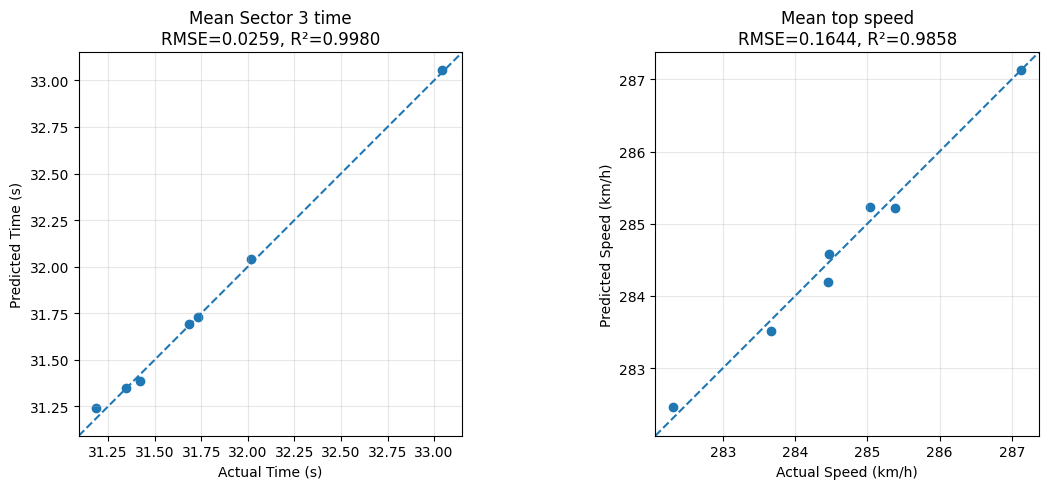

Saved: philipallen04_pr02_validation.png


In [8]:
# 15. Actual-versus-predicted validation figure

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pairs = [
    (axes[0], y_time_test, yhat_time_test, "Mean Sector 3 time", "Time (s)", rmse_time, r2_time),
    (axes[1], y_speed_test, yhat_speed_test, "Mean top speed", "Speed (km/h)", rmse_speed, r2_speed),
]

for ax, actual, predicted, title, label, rmse, r2 in pairs:
    ax.scatter(actual, predicted)
    lo = min(actual.min(), predicted.min())
    hi = max(actual.max(), predicted.max())
    pad = 0.05 * (hi - lo if hi > lo else 1.0)
    lo -= pad
    hi += pad
    ax.plot([lo, hi], [lo, hi], linestyle="--")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Actual {label}")
    ax.set_ylabel(f"Predicted {label}")
    ax.set_title(f"{title}\nRMSE={rmse:.4f}, R²={r2:.4f}")
    ax.grid(alpha=0.3)

fig.tight_layout()
validation_png = f"{PREFIX}_validation.png"
fig.savefig(validation_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", validation_png)

### Validation assessment

Both quadratic response surfaces show strong predictive performance on the seven held-out setup configurations. The Sector 3 model has test RMSE of about **0.026 s** and test R² of about **0.998**, while the top-speed model has test RMSE of about **0.164 km/h** and test R² of about **0.986**. These errors are small relative to the observed setup-to-setup variation and are adequate for the model-based optimization exercise. The main limitation is that only 27 unique setups are available, so the quadratic surfaces should be treated as local surrogates within the tested region rather than verified physical laws.

In [9]:
# 17-18. Refit both surrogate models using all grouped configurations

x1_all = df_grouped["rear_wing_angle_deg"].to_numpy()
x2_all = df_grouped["rear_ride_height_mm"].to_numpy()
Xdm_all = create_design_matrix(x1_all, x2_all)

b_time = np.linalg.pinv(Xdm_all) @ df_grouped["mean_sector_3_time_s"].to_numpy()
b_speed = np.linalg.pinv(Xdm_all) @ df_grouped["mean_top_speed_kph"].to_numpy()

print("Final Sector 3 coefficients:", b_time)
print("Final top-speed coefficients:", b_speed)

def predict_sector_time(x):
    x1, x2 = x
    return (
        b_time[0] + b_time[1]*x1 + b_time[2]*x2
        + b_time[3]*x1**2 + b_time[4]*x2**2 + b_time[5]*x1*x2
    )

def predict_top_speed(x):
    x1, x2 = x
    return (
        b_speed[0] + b_speed[1]*x1 + b_speed[2]*x2
        + b_speed[3]*x1**2 + b_speed[4]*x2**2 + b_speed[5]*x1*x2
    )

check_row = df_grouped.iloc[len(df_grouped)//2]
check_x = np.array([check_row.rear_wing_angle_deg, check_row.rear_ride_height_mm])
print("\nCheck configuration:", check_x)
print("Predicted Sector 3 time:", predict_sector_time(check_x))
print("Measured grouped mean:", check_row.mean_sector_3_time_s)
print("Predicted top speed:", predict_top_speed(check_x))
print("Measured grouped mean:", check_row.mean_top_speed_kph)

Final Sector 3 coefficients: [47.689878 -1.296769 -0.496329  0.054714  0.005883  0.003697]
Final top-speed coefficients: [291.606388  -0.575057  -0.020175  -0.010205  -0.000822   0.002163]

Check configuration: [ 9. 40.]
Predicted Sector 3 time: 31.340928032708188
Measured grouped mean: 31.347379999999998
Predicted top speed: 284.2602979316954
Measured grouped mean: 284.452


# Task III - Optimization with Bounds Only

This task first ignores the minimum top-speed requirement. A dense grid provides a transparent reference search, and L-BFGS-B provides the continuous numerical solution inside the tested bounds.

In [10]:
# 19-21. Tested bounds and 101 x 101 reference grid

wing_bounds = (
    float(df_grouped["rear_wing_angle_deg"].min()),
    float(df_grouped["rear_wing_angle_deg"].max()),
)
ride_height_bounds = (
    float(df_grouped["rear_ride_height_mm"].min()),
    float(df_grouped["rear_ride_height_mm"].max()),
)

x1_grid = np.linspace(wing_bounds[0], wing_bounds[1], 101)
x2_grid = np.linspace(ride_height_bounds[0], ride_height_bounds[1], 101)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

T_grid = predict_sector_time([X1, X2])
V_grid = predict_top_speed([X1, X2])

idx_grid = np.argmin(T_grid)
x_grid_best = np.array([X1.ravel()[idx_grid], X2.ravel()[idx_grid]])
T_grid_best = float(T_grid.ravel()[idx_grid])
V_grid_best = float(predict_top_speed(x_grid_best))

print("Best unconstrained grid point:")
print(f"  Rear-wing angle: {x_grid_best[0]:.4f} deg")
print(f"  Rear ride height: {x_grid_best[1]:.4f} mm")
print(f"  Predicted Sector 3 time: {T_grid_best:.6f} s")
print(f"  Predicted top speed: {V_grid_best:.6f} km/h")

Best unconstrained grid point:
  Rear-wing angle: 10.5200 deg
  Rear ride height: 38.9000 mm
  Predicted Sector 3 time: 31.210586 s
  Predicted top speed: 283.283452 km/h


In [11]:
# 22-24. Bounds-only numerical optimization using L-BFGS-B

def objective(x):
    return float(predict_sector_time(x))

x0 = np.array([np.mean(wing_bounds), np.mean(ride_height_bounds)])
bounds = [wing_bounds, ride_height_bounds]

result_unconstrained = opt.minimize(
    objective,
    x0,
    method="L-BFGS-B",
    bounds=bounds,
)

x_unc = result_unconstrained.x
T_unc = float(predict_sector_time(x_unc))
V_unc = float(predict_top_speed(x_unc))

print("Success:", result_unconstrained.success)
print("Message:", result_unconstrained.message)
print(f"Rear-wing angle: {x_unc[0]:.6f} deg")
print(f"Rear ride height: {x_unc[1]:.6f} mm")
print(f"Predicted Sector 3 time: {T_unc:.6f} s")
print(f"Predicted top speed: {V_unc:.6f} km/h")

Success: True
Message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Rear-wing angle: 10.537268 deg
Rear ride height: 38.873809 mm
Predicted Sector 3 time: 31.210568 s
Predicted top speed: 283.272870 km/h


In [12]:
# 25. Compare continuous and grid solutions

dx1 = x1_grid[1] - x1_grid[0]
dx2 = x2_grid[1] - x2_grid[0]

comparison_unc = pd.DataFrame({
    "quantity": ["wing_deg", "ride_height_mm", "sector_time_s"],
    "grid": [x_grid_best[0], x_grid_best[1], T_grid_best],
    "optimizer": [x_unc[0], x_unc[1], T_unc],
})
comparison_unc["absolute_difference"] = abs(comparison_unc["optimizer"] - comparison_unc["grid"])
display(comparison_unc)

print("Grid spacing in wing angle:", dx1, "deg")
print("Grid spacing in ride height:", dx2, "mm")

,quantity,grid,optimizer,absolute_difference
0,wing_deg,10.520000,10.537268,0.017268
1,ride_height_mm,38.900000,38.873809,0.026191
2,sector_time_s,31.210586,31.210568,0.000019


Grid spacing in wing angle: 0.08000000000000007 deg
Grid spacing in ride height: 0.10000000000000142 mm


The L-BFGS-B solution and the 101 × 101 grid minimum agree closely. Their small difference is expected because the grid can only evaluate discrete increments, while the optimizer searches continuously. This agreement is useful evidence that the numerical solution is not an isolated optimizer artifact.

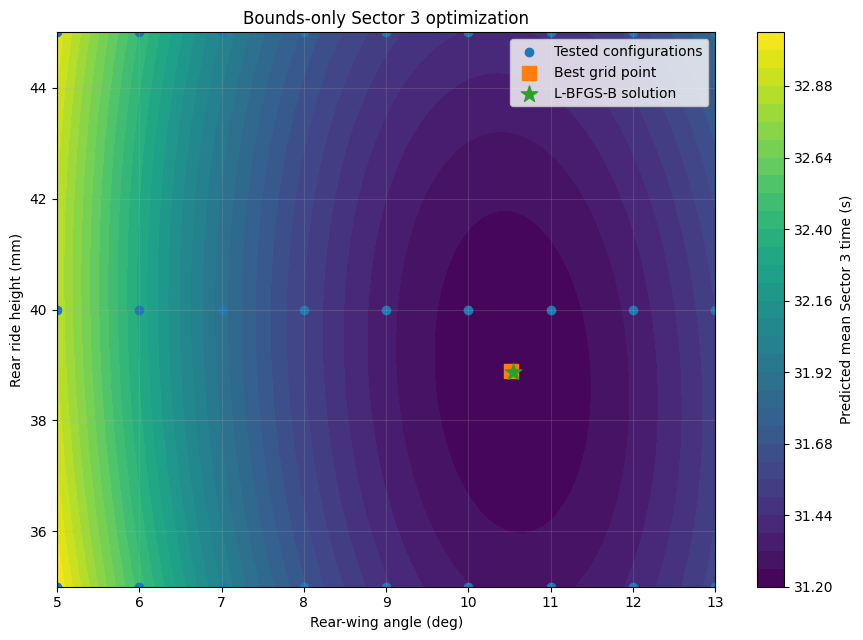

Saved: philipallen04_pr02_unconstrained.png


In [13]:
# 26. Unconstrained response-surface figure

fig, ax = plt.subplots(figsize=(9, 6.5))
contour = ax.contourf(X1, X2, T_grid, levels=30)
fig.colorbar(contour, ax=ax, label="Predicted mean Sector 3 time (s)")
ax.scatter(df_grouped.rear_wing_angle_deg, df_grouped.rear_ride_height_mm, label="Tested configurations")
ax.scatter(*x_grid_best, marker="s", s=90, label="Best grid point")
ax.scatter(*x_unc, marker="*", s=150, label="L-BFGS-B solution")
ax.set_xlabel("Rear-wing angle (deg)")
ax.set_ylabel("Rear ride height (mm)")
ax.set_title("Bounds-only Sector 3 optimization")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
unconstrained_png = f"{PREFIX}_unconstrained.png"
fig.savefig(unconstrained_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", unconstrained_png)

# Task IV - Constrained Engineering Optimization

The engineering requirement is a predicted top speed of at least **284.0 km/h**. The constraint is formulated as `predict_top_speed(x) - 284.0 >= 0` and solved with SLSQP.

In [14]:
# 27-30. Solve the constrained problem

V_min = 284.0

def top_speed_constraint(x):
    return float(predict_top_speed(x) - V_min)

constraint = {"type": "ineq", "fun": top_speed_constraint}

result_constrained = opt.minimize(
    objective,
    x0,
    method="SLSQP",
    bounds=bounds,
    constraints=[constraint],
    options={"ftol": 1e-12, "maxiter": 1000},
)

x_con = result_constrained.x
T_con = float(predict_sector_time(x_con))
V_con = float(predict_top_speed(x_con))
margin_con = V_con - V_min
active_con = abs(margin_con) < 0.05

print("Success:", result_constrained.success)
print("Message:", result_constrained.message)
print(f"Rear-wing angle: {x_con[0]:.6f} deg")
print(f"Rear ride height: {x_con[1]:.6f} mm")
print(f"Predicted Sector 3 time: {T_con:.6f} s")
print(f"Predicted top speed: {V_con:.9f} km/h")
print(f"Constraint margin: {margin_con:.9f} km/h")
print("Constraint approximately active (<0.05 km/h absolute margin):", active_con)

Success: True
Message: Optimization terminated successfully
Rear-wing angle: 9.541825 deg
Rear ride height: 38.327688 mm
Predicted Sector 3 time: 31.268548 s
Predicted top speed: 284.000000000 km/h
Constraint margin: 0.000000000 km/h
Constraint approximately active (<0.05 km/h absolute margin): True


In [15]:
# 31-32. Initial-guess sensitivity study

initial_guesses = [
    [9, 40],
    [5, 35],
    [13, 45],
    [6, 44],
    [12, 36],
]

optimization_rows = []
for start in initial_guesses:
    r = opt.minimize(
        objective,
        np.asarray(start, dtype=float),
        method="SLSQP",
        bounds=bounds,
        constraints=[constraint],
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    x_opt = r.x
    optimization_rows.append({
        "initial_x1": start[0],
        "initial_x2": start[1],
        "optimal_x1": x_opt[0],
        "optimal_x2": x_opt[1],
        "sector_time_s": float(predict_sector_time(x_opt)),
        "top_speed_kph": float(predict_top_speed(x_opt)),
        "constraint_margin_kph": float(top_speed_constraint(x_opt)),
        "success": bool(r.success),
    })

df_optimization_runs = pd.DataFrame(optimization_rows)
display(df_optimization_runs)

optimization_file = f"{PREFIX}_optimization_runs.csv"
df_optimization_runs.to_csv(optimization_file, index=False)
print("Saved:", optimization_file)
print("Spread in optimal wing:", df_optimization_runs.optimal_x1.max() - df_optimization_runs.optimal_x1.min())
print("Spread in optimal ride height:", df_optimization_runs.optimal_x2.max() - df_optimization_runs.optimal_x2.min())

,initial_x1,initial_x2,optimal_x1,optimal_x2,sector_time_s,top_speed_kph,constraint_margin_kph,success
0,9,40,9.541825,38.327688,31.268548,284.0,0.000000e+00,True
1,5,35,9.541826,38.327669,31.268548,284.0,5.684342e-14,True
2,13,45,9.541826,38.327671,31.268548,284.0,-3.808509e-12,True
3,6,44,9.541827,38.327659,31.268548,284.0,-1.136868e-13,True
4,12,36,9.541826,38.327678,31.268548,284.0,5.684342e-14,True


Saved: philipallen04_pr02_optimization_runs.csv
Spread in optimal wing: 2.6595939299767224e-06
Spread in optimal ride height: 2.9199077289376874e-05


All tested initial guesses converge to essentially the same constrained candidate. This reduces concern that the reported SLSQP solution is being driven by the starting point within the tested region.

In [16]:
# 33-34. Grid-based feasibility verification

feasible_mask = V_grid >= V_min
print(f"Feasible grid points: {feasible_mask.sum()} of {feasible_mask.size}")

T_feasible = np.where(feasible_mask, T_grid, np.inf)
idx_feasible = np.argmin(T_feasible)
x_grid_feasible = np.array([
    X1.ravel()[idx_feasible],
    X2.ravel()[idx_feasible],
])
T_grid_feasible = float(T_grid.ravel()[idx_feasible])
V_grid_feasible = float(V_grid.ravel()[idx_feasible])

print("Best feasible grid point:")
print(f"  Wing: {x_grid_feasible[0]:.4f} deg")
print(f"  Ride height: {x_grid_feasible[1]:.4f} mm")
print(f"  Predicted Sector 3 time: {T_grid_feasible:.6f} s")
print(f"  Predicted top speed: {V_grid_feasible:.6f} km/h")
print("\nDifference from SLSQP:")
print("  Wing:", x_grid_feasible[0] - x_con[0], "deg")
print("  Ride height:", x_grid_feasible[1] - x_con[1], "mm")
print("  Sector time:", T_grid_feasible - T_con, "s")

Feasible grid points: 5569 of 10201
Best feasible grid point:
  Wing: 9.5600 deg
  Ride height: 38.1000 mm
  Predicted Sector 3 time: 31.269140 s
  Predicted top speed: 284.001706 km/h

Difference from SLSQP:
  Wing: 0.018175325496171624 deg
  Ride height: -0.22768826783316598 mm
  Sector time: 0.0005921323505369003 s


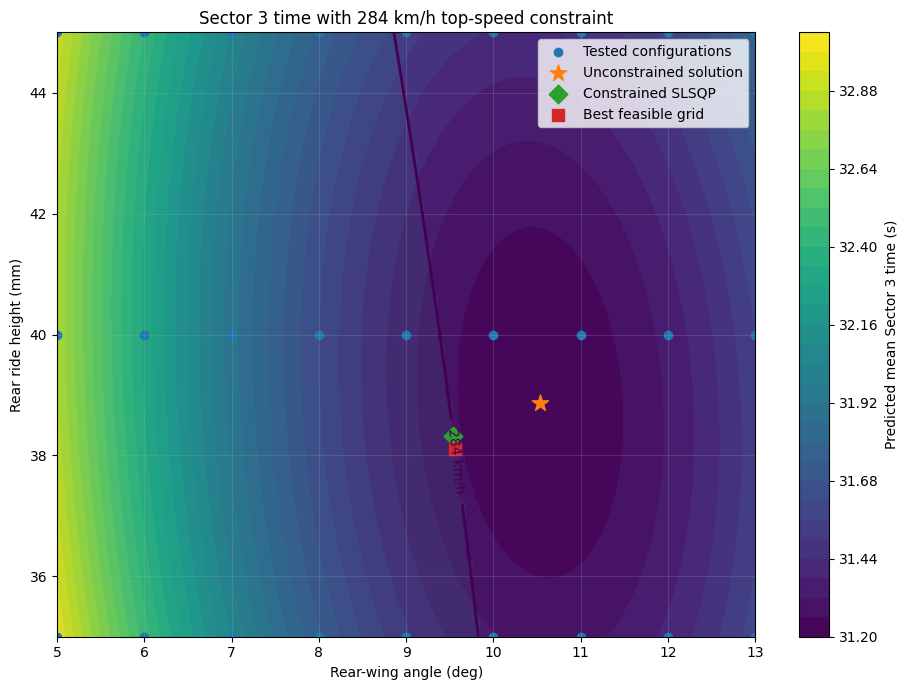

Saved: philipallen04_pr02_constrained.png


In [17]:
# 35-37. Constrained optimization visualization

fig, ax = plt.subplots(figsize=(9.5, 7))
contour = ax.contourf(X1, X2, T_grid, levels=30)
fig.colorbar(contour, ax=ax, label="Predicted mean Sector 3 time (s)")

# Top-speed boundary
speed_boundary = ax.contour(X1, X2, V_grid, levels=[V_min], linewidths=2)
ax.clabel(speed_boundary, fmt={V_min: "284 km/h"})

# Light overlay of feasible region boundary via hatching-like alpha contour
ax.contourf(X1, X2, feasible_mask.astype(float), levels=[0.5, 1.5], alpha=0.12)

ax.scatter(df_grouped.rear_wing_angle_deg, df_grouped.rear_ride_height_mm, label="Tested configurations")
ax.scatter(*x_unc, marker="*", s=150, label="Unconstrained solution")
ax.scatter(*x_con, marker="D", s=90, label="Constrained SLSQP")
ax.scatter(*x_grid_feasible, marker="s", s=75, label="Best feasible grid")

ax.set_xlabel("Rear-wing angle (deg)")
ax.set_ylabel("Rear ride height (mm)")
ax.set_title("Sector 3 time with 284 km/h top-speed constraint")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
constrained_png = f"{PREFIX}_constrained.png"
fig.savefig(constrained_png, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", constrained_png)

In [18]:
# 38. Quantify engineering tradeoff caused by the speed constraint

engineering_comparison = pd.DataFrame([
    {
        "solution": "Unconstrained",
        "wing_deg": x_unc[0],
        "ride_height_mm": x_unc[1],
        "sector_time_s": T_unc,
        "top_speed_kph": V_unc,
    },
    {
        "solution": "Constrained SLSQP",
        "wing_deg": x_con[0],
        "ride_height_mm": x_con[1],
        "sector_time_s": T_con,
        "top_speed_kph": V_con,
    },
])
display(engineering_comparison)

print(f"Sector 3 penalty from constraint: {T_con - T_unc:.6f} s")
print(f"Top-speed gain from constraint: {V_con - V_unc:.6f} km/h")
print(f"Wing change: {x_con[0] - x_unc[0]:.6f} deg")
print(f"Ride-height change: {x_con[1] - x_unc[1]:.6f} mm")

,solution,wing_deg,ride_height_mm,sector_time_s,top_speed_kph
0,Unconstrained,10.537268,38.873809,31.210568,283.27287
1,Constrained SLSQP,9.541825,38.327688,31.268548,284.00000


Sector 3 penalty from constraint: 0.057981 s
Top-speed gain from constraint: 0.727130 km/h
Wing change: -0.995443 deg
Ride-height change: -0.546121 mm


### Engineering comparison

The bounds-only minimum is slightly faster in predicted Sector 3 time, but it violates the 284 km/h requirement. Imposing the top-speed constraint moves the recommendation to lower wing angle and lower ride height. The constrained solution sacrifices only about **0.058 s** of predicted Sector 3 performance while gaining about **0.727 km/h** of predicted top speed, placing the candidate directly on the required speed boundary. Because it satisfies the stated engineering requirement and is supported by both SLSQP and the feasible grid search, the constrained solution is more defensible than the unconstrained minimum.

# Task V - Penalty Functions and Final Recommendation

In [19]:
# 39-43. Quadratic penalty study

def penalized_objective(x, rho):
    violation = max(0.0, V_min - float(predict_top_speed(x)))
    return float(predict_sector_time(x)) + rho * violation**2

penalty_rows = []
penalty_results = {}
for rho in [0.1, 1, 10, 100]:
    r = opt.minimize(
        penalized_objective,
        x0,
        args=(rho,),
        method="L-BFGS-B",
        bounds=bounds,
    )
    penalty_results[rho] = r
    x_pen = r.x
    T_pen = float(predict_sector_time(x_pen))
    V_pen = float(predict_top_speed(x_pen))
    violation = max(0.0, V_min - V_pen)
    penalty_rows.append({
        "rho": rho,
        "rear_wing_angle_deg": x_pen[0],
        "rear_ride_height_mm": x_pen[1],
        "sector_time_s": T_pen,
        "top_speed_kph": V_pen,
        "violation_kph": violation,
        "penalized_objective": float(penalized_objective(x_pen, rho)),
    })

df_penalty = pd.DataFrame(penalty_rows)
display(df_penalty)

penalty_file = f"{PREFIX}_penalty.csv"
df_penalty.to_csv(penalty_file, index=False)
print("Saved:", penalty_file)

,rho,rear_wing_angle_deg,rear_ride_height_mm,sector_time_s,top_speed_kph,violation_kph,penalized_objective
0,0.1,10.062880,38.624143,31.223685,283.621025,0.378975,31.238047
1,1.0,9.641823,38.386140,31.257452,283.927561,0.072439,31.262699
2,10.0,9.552865,38.334065,31.267266,283.992016,0.007984,31.267903
3,100.0,9.542942,38.328308,31.268418,283.999193,0.000807,31.268483


Saved: philipallen04_pr02_penalty.csv


As the penalty parameter increases, violating the top-speed requirement becomes progressively more expensive. The recommended design therefore moves toward the explicit SLSQP constraint boundary and the speed violation shrinks. At `rho = 100`, the penalty solution is extremely close to the constrained solution, although it remains very slightly below 284 km/h because a finite quadratic penalty does not mathematically force exact feasibility.

In [20]:
# 44-45. Recommendation summary

x_pen100 = penalty_results[100].x

def solution_row(name, x, feasibility_tol=1e-6):
    T = float(predict_sector_time(x))
    V = float(predict_top_speed(x))
    margin = V - V_min
    return {
        "solution": name,
        "rear_wing_angle_deg": float(x[0]),
        "rear_ride_height_mm": float(x[1]),
        "sector_time_s": T,
        "top_speed_kph": V,
        "constraint_margin_kph": margin,
        "feasible": bool(margin >= -feasibility_tol),
    }

df_recommendation = pd.DataFrame([
    solution_row("Unconstrained (L-BFGS-B)", x_unc),
    solution_row("Constrained (SLSQP)", x_con),
    solution_row("Best feasible grid point", x_grid_feasible),
    solution_row("Penalty rho = 100", x_pen100),
])

display(df_recommendation)
recommendation_file = f"{PREFIX}_recommendation.csv"
df_recommendation.to_csv(recommendation_file, index=False)
print("Saved:", recommendation_file)

x_recommended = x_con
print("\nFINAL MODEL-BASED RECOMMENDED CANDIDATE (requires verification)")
print(f"  Rear-wing angle: {x_recommended[0]:.2f} deg")
print(f"  Rear ride height: {x_recommended[1]:.2f} mm")
print(f"  Predicted Sector 3 time: {predict_sector_time(x_recommended):.3f} s")
print(f"  Predicted top speed: {predict_top_speed(x_recommended):.3f} km/h")

,solution,rear_wing_angle_deg,rear_ride_height_mm,sector_time_s,top_speed_kph,constraint_margin_kph,feasible
0,Unconstrained (L-BFGS-B),10.537268,38.873809,31.210568,283.272870,-0.727130,False
1,Constrained (SLSQP),9.541825,38.327688,31.268548,284.000000,0.000000,True
2,Best feasible grid point,9.560000,38.100000,31.269140,284.001706,0.001706,True
3,Penalty rho = 100,9.542942,38.328308,31.268418,283.999193,-0.000807,False


Saved: philipallen04_pr02_recommendation.csv

FINAL MODEL-BASED RECOMMENDED CANDIDATE (requires verification)
  Rear-wing angle: 9.54 deg
  Rear ride height: 38.33 mm
  Predicted Sector 3 time: 31.269 s
  Predicted top speed: 284.000 km/h


## Final Engineering Recommendation

The recommended model-based candidate is approximately **9.54° rear-wing angle and 38.33 mm rear ride height**. The final quadratic surrogates predict a mean Sector 3 time of approximately **31.269 s** and a top speed of approximately **284.000 km/h**.

This candidate is preferable to the unconstrained minimum because the unconstrained solution predicts a slightly lower Sector 3 time but fails the minimum top-speed requirement. The speed constraint is active at the SLSQP solution, which physically means that the optimization uses essentially all of the allowed straight-line-speed tradeoff in exchange for Sector 3 performance. Five substantially different starting points converge to the same candidate, and the dense feasible-grid search identifies a nearby solution with nearly identical predicted Sector 3 time. These independent checks support the numerical recommendation.

The penalty study shows that increasing `rho` steadily reduces the top-speed violation and moves the penalty solution toward the explicitly constrained result. A finite penalty, however, does not guarantee exact feasibility, which is why the SLSQP solution is the preferred engineering recommendation.

This remains a **surrogate-model recommendation, not a confirmed physical optimum**. The data cover only 27 tested setup configurations and the fitted models are quadratic approximations. A follow-up track test should evaluate the recommended setup and nearby perturbations in wing angle and ride height under comparable conditions. If track testing is unavailable, a higher-fidelity vehicle/aerodynamic simulation should be used to confirm both Sector 3 performance and top speed before the setup is treated as physically validated.

## Reproducibility and Output Check

In [21]:
# Confirm all required generated files exist
required_outputs = [
    f"{PREFIX}_grouped.csv",
    f"{PREFIX}_validation.csv",
    f"{PREFIX}_optimization_runs.csv",
    f"{PREFIX}_penalty.csv",
    f"{PREFIX}_recommendation.csv",
    f"{PREFIX}_validation.png",
    f"{PREFIX}_unconstrained.png",
    f"{PREFIX}_constrained.png",
]

for path in required_outputs:
    print(f"{path}: {'OK' if Path(path).exists() else 'MISSING'}")

philipallen04_pr02_grouped.csv: OK
philipallen04_pr02_validation.csv: OK
philipallen04_pr02_optimization_runs.csv: OK
philipallen04_pr02_penalty.csv: OK
philipallen04_pr02_recommendation.csv: OK
philipallen04_pr02_validation.png: OK
philipallen04_pr02_unconstrained.png: OK
philipallen04_pr02_constrained.png: OK
